# Flight Delay Analysis
## Exploratory Data Analysis
* **Goal:** Understand the structure, quality and charachteristics of the dataset.

In [3]:
# Import libaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [4]:
# Safe data loading with try / except
try:
    df = pd.read_csv('../data/flight_data_2024.csv')
    print('Data Load successfully')
except FileNotFoundError:
    print('File not Found - check Path')
except Exception as e:
    print('Other Error occurr - check {e}')

/var/folders/q8/v6_548714bg4cjmlh_2vhkxh0000gn/T/ipykernel_15274/1565152846.py:3: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/flight_data_2024.csv')


Data Load successfully


In [5]:
df.columns[24]

'cancellation_code'

**Note**: Column 24 - Cancellation Code needs further inspection

In [6]:
# Check cols and rows
print(f'Cols: {df.shape[0]} -- Rows: {df.shape[1]}')

Cols: 7079081 -- Rows: 35


In [7]:
# Inspection of Dataset
df.describe(include='all')

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,7079081.0,7.079081e+06,7.079081e+06,7.079081e+06,7079081,7079081,7.079080e+06,7079081,7079081,7079081,...,7.079081e+06,7.079080e+06,6.965267e+06,6.965267e+06,7.079081e+06,7.079081e+06,7.079081e+06,7.079081e+06,7.079081e+06,7.079081e+06
unique,NaN,NaN,NaN,NaN,366,15,NaN,348,342,52,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,2024-12-01,WN,NaN,ATL,"Chicago, IL",Texas,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,21764,1419419,NaN,341910,359685,751839,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2024.0,6.584868e+00,1.578445e+01,3.981945e+00,NaN,NaN,2.504623e+03,NaN,NaN,NaN,...,2.471931e-03,1.467665e+02,1.412151e+02,1.149997e+02,8.339062e+02,5.060440e+00,8.752369e-01,2.771828e+00,2.541686e-02,5.929302e+00
std,0.0,3.396806e+00,8.786433e+00,2.012279e+00,NaN,NaN,1.652253e+03,NaN,NaN,NaN,...,4.965703e-02,7.238692e+01,7.230781e+01,7.036955e+01,5.962536e+02,3.572703e+01,1.542974e+01,1.546485e+01,1.422602e+00,3.106135e+01
min,2024.0,1.000000e+00,1.000000e+00,1.000000e+00,NaN,NaN,1.000000e+00,NaN,NaN,NaN,...,0.000000e+00,-1.600000e+02,1.500000e+01,5.000000e+00,1.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2024.0,4.000000e+00,8.000000e+00,2.000000e+00,NaN,NaN,1.151000e+03,NaN,NaN,NaN,...,0.000000e+00,9.300000e+01,8.800000e+01,6.300000e+01,3.990000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2024.0,7.000000e+00,1.600000e+01,4.000000e+00,NaN,NaN,2.227000e+03,NaN,NaN,NaN,...,0.000000e+00,1.300000e+02,1.250000e+02,9.800000e+01,6.800000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2024.0,1.000000e+01,2.300000e+01,6.000000e+00,NaN,NaN,3.717000e+03,NaN,NaN,NaN,...,0.000000e+00,1.770000e+02,1.720000e+02,1.450000e+02,1.069000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [8]:
df.head()

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


In [9]:
# Check missing values
df.isna().sum()

year                         0
month                        0
day_of_month                 0
day_of_week                  0
fl_date                      0
op_unique_carrier            0
op_carrier_fl_num            1
origin                       0
origin_city_name             0
origin_state_nm              0
dest                         0
dest_city_name               0
dest_state_nm                0
crs_dep_time                 0
dep_time                 92659
dep_delay                92970
taxi_out                 95734
wheels_off               95734
wheels_on                97856
taxi_in                  97856
crs_arr_time                 0
arr_time                 97854
arr_delay               113814
cancelled                    0
cancellation_code      6982766
diverted                     0
crs_elapsed_time             1
actual_elapsed_time     113814
air_time                113814
distance                     0
carrier_delay                0
weather_delay                0
nas_dela

**Note:** A lot of missing values, especially almost all cancellation codes value are missing which should be handeld in Feature Engineering

In [10]:
df[['year', 'month', 'day_of_month', 'day_of_week']].dtypes
df[['year', 'month', 'day_of_month', 'day_of_week']].head()

,year,month,day_of_month,day_of_week
0,2024,1,1,1
1,2024,1,1,1
2,2024,1,1,1
3,2024,1,1,1
4,2024,1,1,1


In [11]:
# Convert into pandas daytime
df['date'] = pd.to_datetime({
    'year': df['year'],
    'month': df['month'],
    'day': df['day_of_month'] 
})

In [12]:
df['year'].min()

2024

In [13]:
df['date'].head()

0   2024-01-01
1   2024-01-01
2   2024-01-01
3   2024-01-01
4   2024-01-01
Name: date, dtype: datetime64[ns]

In [14]:
top_five_airports_dep = df.groupby('origin')['year'].size().sort_values(ascending=False).head(5)
top_five_airports_dep

origin
ATL    341910
DFW    313582
DEN    308645
ORD    280052
CLT    217574
Name: year, dtype: int64

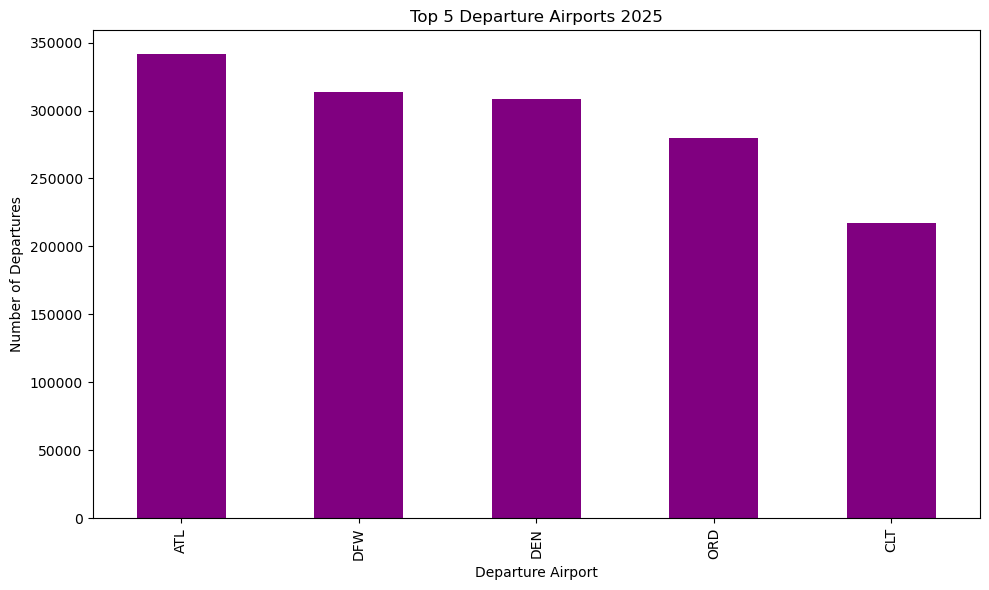

In [15]:
plt.figure(figsize=(10,6))
top_five_airports_dep.plot(kind='bar', color='purple')
plt.title('Top 5 Departure Airports 2025')
plt.xlabel('Departure Airport')
plt.ylabel('Number of Departures')

plt.tight_layout()
plt.show()

**Note:** The Top 5 Departure Airports in 2024 with the hightest numbers of Departures are:

- Atlanta (ATL) with 341910
- Dallas (DFW) with 313582
- Denver (DEN) with 308645
- Chicago O'Hare (ORD) with 280052
- Charlotte Douglas (CLT) with 217574

In [16]:
top_five_airports_dest = df.groupby('dest')['year'].count().sort_values(ascending=False).head(5)
top_five_airports_dest

dest
ATL    341844
DFW    313568
DEN    308609
ORD    280009
CLT    217545
Name: year, dtype: int64

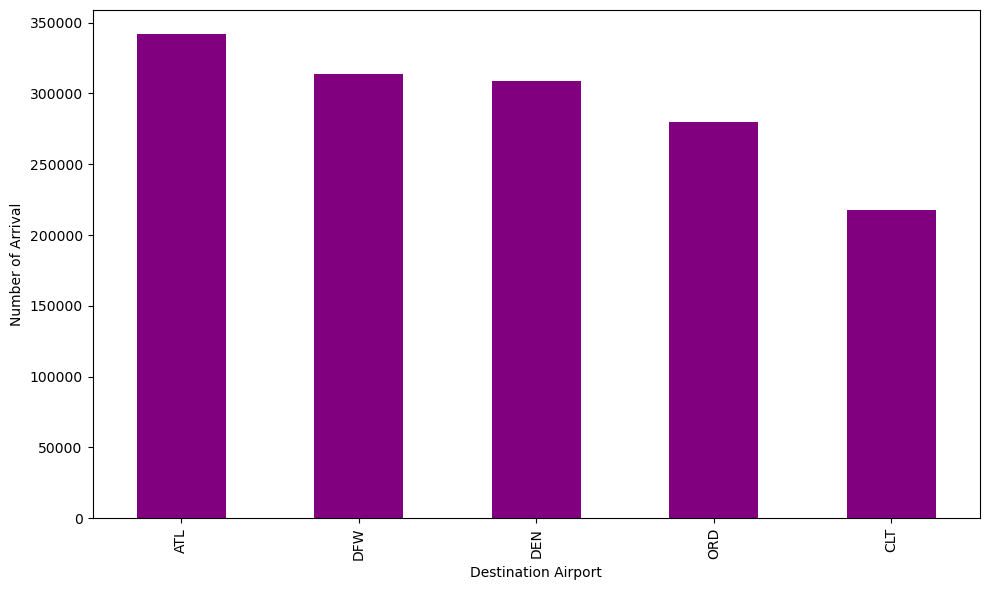

In [17]:
plt.figure(figsize=(10,6))
top_five_airports_dest.plot(kind='bar', color='purple')
plt.title('')
plt.xlabel('Destination Airport')
plt.ylabel('Number of Arrival')

plt.tight_layout()
plt.show()

**Note:** Top 5 Destination Airports are also:

- Atlanta (ATL) with 341844
- Dallas (DFW) with 313568
- Denver (DEN) with 308609
- Chicago O'Hare (ORD) with 280009
- Charlotte Douglas (CLT) with 217574

In [18]:
print(top_five_airports_dep - top_five_airports_dest)

origin
ATL    66
DFW    14
DEN    36
ORD    43
CLT    29
Name: year, dtype: int64


In [19]:
df[['crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off',
       'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay']].head()

,crs_dep_time,dep_time,dep_delay,taxi_out,wheels_off,wheels_on,taxi_in,crs_arr_time,arr_time,arr_delay
0,1252,1247.0,-5.0,31.0,1318.0,1442.0,7.0,1508,1449.0,-19.0
1,1015,1001.0,-14.0,20.0,1021.0,1249.0,6.0,1325,1255.0,-30.0
2,1415,1411.0,-4.0,21.0,1432.0,1533.0,8.0,1601,1541.0,-20.0
3,1650,1643.0,-7.0,13.0,1656.0,1747.0,12.0,1841,1759.0,-42.0
4,1015,1010.0,-5.0,21.0,1031.0,1016.0,4.0,1034,1020.0,-14.0


In [20]:
# Convert time
time_convert = ['crs_dep_time', 'dep_time', 'wheels_off',
       'wheels_on', 'crs_arr_time', 'arr_time']

for cols in time_convert:
    df[cols] = pd.to_datetime(
        df[cols].astype('Int64').astype(str).str.zfill(4), 
        format='%H%M',
        errors='coerce'
    )

In [21]:
df['crs_datetime'] = pd.to_datetime(
    df['date'].dt.strftime('%Y-%m-%d') + ' ' +
    df['crs_dep_time'].dt.strftime('%H:%M:%S')
)

df['dep_datetime'] = pd.to_datetime(
    df['date'].dt.strftime('%Y-%m-%d') + ' ' +
    df['dep_time'].dt.strftime('%H:%M:%S')
)

In [22]:
df[['crs_datetime','dep_datetime']].head()

,crs_datetime,dep_datetime
0,2024-01-01 12:52:00,2024-01-01 12:47:00
1,2024-01-01 10:15:00,2024-01-01 10:01:00
2,2024-01-01 14:15:00,2024-01-01 14:11:00
3,2024-01-01 16:50:00,2024-01-01 16:43:00
4,2024-01-01 10:15:00,2024-01-01 10:10:00


In [23]:
df[['date', 'crs_datetime', 'dep_datetime']].dtypes

date            datetime64[ns]
crs_datetime    datetime64[ns]
dep_datetime    datetime64[ns]
dtype: object

In [24]:
df['arr_date'] = df['date'].copy()
df.loc[df['arr_time'] < df['dep_time'], 'arr_date'] += pd.Timedelta(days=1)

df['crs_arr_date'] = df['date'].copy()
df.loc[df['crs_arr_time'] < df['crs_dep_time'], 'crs_arr_date'] += pd.Timedelta(days=1)

In [25]:
df['crs_arr_datetime'] = pd.to_datetime(
    df['crs_arr_date'].dt.strftime('%Y-%m-%d') + ' ' +
    df['crs_arr_time'].dt.strftime('%H:%M:%S')
)

df['arr_datetime'] = pd.to_datetime(
    df['arr_date'].dt.strftime('%Y-%m-%d') + ' ' +
    df['arr_time'].dt.strftime('%H:%M:%S')
)

In [26]:
df[['crs_datetime', 'dep_datetime', 'arr_date', 'crs_arr_date',
       'crs_arr_datetime', 'arr_datetime']].head()

,crs_datetime,dep_datetime,arr_date,crs_arr_date,crs_arr_datetime,arr_datetime
0,2024-01-01 12:52:00,2024-01-01 12:47:00,2024-01-01,2024-01-01,2024-01-01 15:08:00,2024-01-01 14:49:00
1,2024-01-01 10:15:00,2024-01-01 10:01:00,2024-01-01,2024-01-01,2024-01-01 13:25:00,2024-01-01 12:55:00
2,2024-01-01 14:15:00,2024-01-01 14:11:00,2024-01-01,2024-01-01,2024-01-01 16:01:00,2024-01-01 15:41:00
3,2024-01-01 16:50:00,2024-01-01 16:43:00,2024-01-01,2024-01-01,2024-01-01 18:41:00,2024-01-01 17:59:00
4,2024-01-01 10:15:00,2024-01-01 10:10:00,2024-01-01,2024-01-01,2024-01-01 10:34:00,2024-01-01 10:20:00


In [27]:
df['flight_duration'] = df['arr_datetime'] - df['dep_datetime']
df['flight_duration'].sort_values(ascending=False).head(10)

1250825   0 days 23:59:00
6611704   0 days 23:59:00
6959841   0 days 23:59:00
5831444   0 days 23:59:00
2459439   0 days 23:59:00
4348692   0 days 23:59:00
6611710   0 days 23:59:00
1850770   0 days 23:59:00
6360888   0 days 23:59:00
3386823   0 days 23:59:00
Name: flight_duration, dtype: timedelta64[ns]

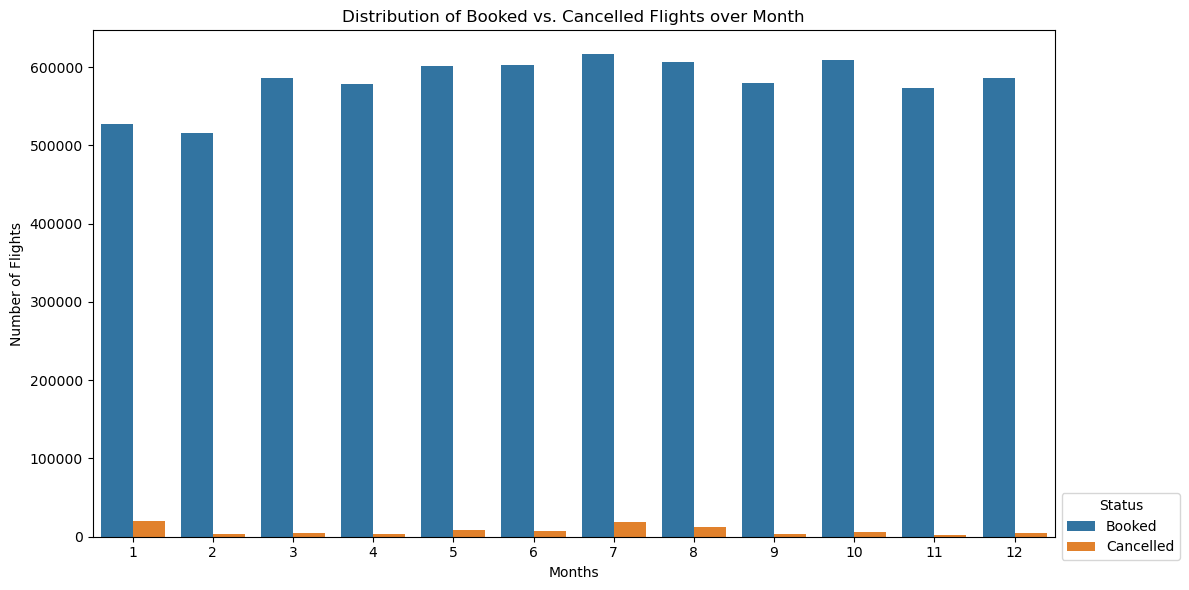

In [28]:
# Check the count of flights by month
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='month', hue='cancelled')

plt.title('Distribution of Booked vs. Cancelled Flights over Month')
plt.xlabel('Months')
plt.ylabel('Number of Flights')

plt.legend(bbox_to_anchor=(1, 0.1), title='Status', labels=['Booked', 'Cancelled'])

plt.tight_layout()
plt.show()

**Monthly Distribution of Flights and Cancellations**

The distribution shows that the number of flights remains relatively high throughout the year, with more than 500,000 flights in most months.

Flight activity appears to increase slightly during the summer months and around the winter holiday season.

Cancelled flights represent only a small proportion of total flights. January records the highest number of cancellations, followed by July.

**Further investigation:** Since the absolute number of cancellations can be influenced by the total number of flights, comparing monthly cancellation rates would provide a more meaningful picture of seasonal cancellation patterns.

In [29]:
# Average departure / arrival delay by destination
df.groupby('origin')['dep_delay'].mean().sort_values(ascending=False)


origin
MGW    72.621622
EWN    68.404255
HTS    42.788835
SMX    40.509434
CKB    37.024752
         ...    
YAK    -3.229577
BTM    -4.975362
ADK    -6.062500
AKN    -6.432584
SCC    -7.059675
Name: dep_delay, Length: 348, dtype: float64

In [30]:
df.groupby('dest')['arr_delay'].mean().sort_values(ascending=False)

dest
EAU    69.266667
MGW    54.166667
EWN    38.708333
HOB    34.437071
CNY    23.620690
         ...    
EAR    -3.970297
BTM    -4.989840
ADK    -7.255319
SPN    -9.456044
STC   -14.944828
Name: arr_delay, Length: 348, dtype: float64

**Average Departure and Arrival Delays by Airport**

The analysis shows that smaller regional airports dominate the top five rankings for both average departure and arrival delays.

MGW (Morgantown Municipal Airport) records the highest average departure delay at approximately 73 minutes, while EAU (Chippewa Valley Regional Airport) has the highest average arrival delay at approximately 69 minutes.

MGW (Morgantown Municipal Airport) and EWN (Coastal Carolina Regional Airport) appear in both rankings, suggesting that these airports experience considerable delays in both directions.

However, average delay values alone do not provide the full picture. The number of flights per airport should also be considered, as smaller sample sizes and individual extreme delays can significantly influence the average.

In [31]:
df.columns

Index(['year', 'month', 'day_of_month', 'day_of_week', 'fl_date',
       'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name',
       'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm',
       'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off',
       'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay',
       'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time',
       'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay',
       'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay',
       'date', 'crs_datetime', 'dep_datetime', 'arr_date', 'crs_arr_date',
       'crs_arr_datetime', 'arr_datetime', 'flight_duration'],
      dtype='object')

In [32]:
delay_dep_airports = (df.groupby('origin')['weather_delay']
    .agg(['sum', 'mean', 'count'])
    .sort_values(by='sum',ascending=False)
    .head(10)
)
delay_dep_airports

,sum,mean,count
origin,,,
DFW,513665,1.638056,313582
ORD,356520,1.273049,280052
CLT,336218,1.545304,217574
DEN,211328,0.684696,308645
ATL,210875,0.616756,341910
IAH,177656,1.532310,115940
MCO,163162,1.022619,159553
DTW,143945,1.095747,131367
MSP,138260,1.090559,126779


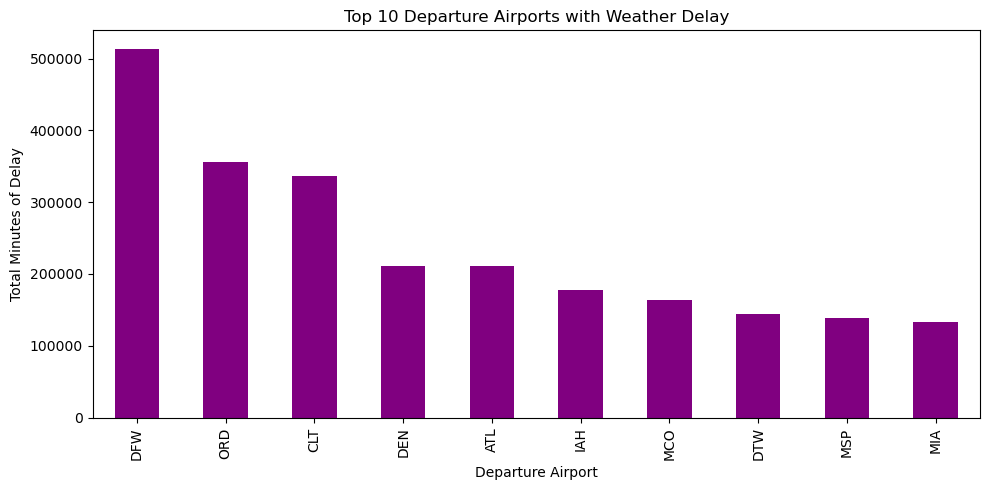

In [33]:
plt.figure(figsize=(10, 5))
delay_dep_airports['sum'].plot(kind='bar', color='purple')
plt.title('Top 10 Departure Airports with Weather Delay')
plt.xlabel('Departure Airport')
plt.ylabel('Total Minutes of Delay')

plt.tight_layout()
plt.show()

**Top 10 Departure Airports with Weather Delays**

The chart clearly shows that DFW (Dallas/Fort Worth International Airport) has the highest total number of weather-related delay minutes, with over 500,000 minutes. It is followed by ORD (Chicago O'Hare International Airport) and CLT (Charlotte Douglas International Airport), both with more than 300,000 minutes of weather-related delays.

Due to the high volume of departing flights at these airports, the average weather-related delay is considerably lower, ranging between approximately 1 and 2 minutes per flight.

In [34]:
delay_arr_airports = (df.groupby('dest')['weather_delay']
    .agg(['sum', 'mean', 'count'])
    .sort_values(by='sum',ascending=False)
    .head(10)
)
delay_arr_airports

,sum,mean,count
dest,,,
DFW,597499,1.905485,313568
ORD,300076,1.071666,280009
ATL,240434,0.703344,341844
DEN,226275,0.733209,308609
CLT,206010,0.946976,217545
MSP,163942,1.292989,126793
DTW,155389,1.182925,131360
LAX,151410,0.780287,194044
LGA,149278,0.918803,162470


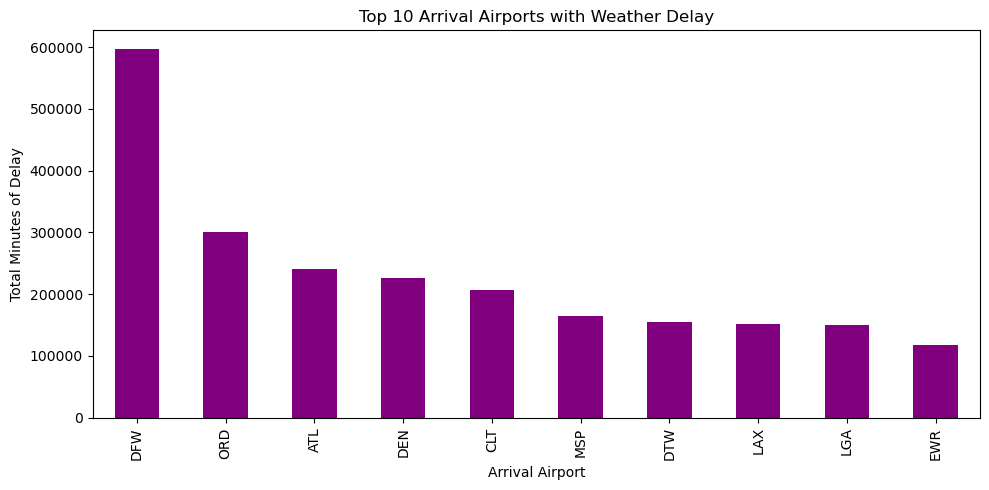

In [35]:
plt.figure(figsize=(10, 5))
delay_arr_airports['sum'].plot(kind='bar', color='purple')
plt.title('Top 10 Arrival Airports with Weather Delay')
plt.xlabel('Arrival Airport')
plt.ylabel('Total Minutes of Delay')

plt.tight_layout()
plt.show()

**Top 10 Arrival Airports with Weather Delays**

The chart shows a significant difference compared to the departure airports. DFW (Dallas/Fort Worth International Airport) ranks first, with almost 600,000 minutes of weather-related delays. ORD (Chicago O'Hare International Airport) follows with nearly 300,000 minutes, while ATL (Hartsfield-Jackson Atlanta International Airport) records approximately 250,000 minutes.

This clearly indicates that DFW has almost twice as many accumulated weather-related delay minutes as ORD.

In [36]:
dfw = df[(df['origin'] == "DFW") | (df['dest'] == "DFW")]
dfw.groupby('month').size()

month
1     47158
2     45354
3     51131
4     49813
5     54215
6     55375
7     58164
8     55801
9     52403
10    55723
11    50382
12    51631
dtype: int64

In [37]:
# all delays for top 10 airports
(df.groupby('origin')
    [['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']]
    .agg('sum')
    .sort_values(by='carrier_delay', ascending=False)
    .head(10)
) 

,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
origin,,,,,
ATL,1990392,210875,843741,4101,1263070
DFW,1891223,513665,816922,5783,2937936
ORD,1508397,356520,972900,4591,1948958
DEN,1492983,211328,788925,6520,1840419
CLT,1254635,336218,578458,16945,2012975
DTW,921465,143945,352023,2158,384473
LAX,898245,76497,498914,3979,932156
LAS,864637,67211,497676,3495,1113788
PHX,863755,49244,345978,3951,1027303


In [38]:
delays_departure = (
    df.groupby('origin')
    .agg(
        flights=('origin', 'size'),
        carrier_delay=('carrier_delay', 'sum'),
        weather_delay=('weather_delay', 'sum'),
        nas_delay=('nas_delay', 'sum'),
        security_delay=('security_delay', 'sum'),
        late_aircraft_delay=('late_aircraft_delay', 'sum')
    )
)

delays_departure['carrier_per_flight'] = (delays_departure['carrier_delay'] / delays_departure['flights'])
delays_departure['weather_per_flight'] = (delays_departure['weather_delay'] / delays_departure['flights'])
delays_departure['nas_per_flight'] = (delays_departure['nas_delay'] / delays_departure['flights'])
delays_departure['seco_per_flight'] = (delays_departure['security_delay'] / delays_departure['flights'])
delays_departure['late_aircraft_per_flight'] = (delays_departure['late_aircraft_delay'] / delays_departure['flights'])

In [39]:
delays_departure.sort_values(by='weather_per_flight', ascending=False).head(10)

,flights,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,carrier_per_flight,weather_per_flight,nas_per_flight,seco_per_flight,late_aircraft_per_flight
origin,,,,,,,,,,,
STC,149,126,1374,278,43,421,0.845638,9.221477,1.865772,0.288591,2.825503
WYS,313,2873,2598,145,0,190,9.178914,8.300319,0.463259,0.000000,0.607029
LCH,1086,15177,8690,1701,0,3385,13.975138,8.001842,1.566298,0.000000,3.116943
ASE,7888,67784,57044,35753,2602,53499,8.593306,7.231744,4.532581,0.329868,6.782328
BPT,730,3421,5106,1194,0,1931,4.686301,6.994521,1.635616,0.000000,2.645205
PBG,501,4950,3341,3821,0,4140,9.880240,6.668663,7.626747,0.000000,8.263473
APN,629,8588,3974,785,35,0,13.653418,6.317965,1.248013,0.055644,0.000000
PLN,846,10588,4947,513,16,0,12.515366,5.847518,0.606383,0.018913,0.000000
ROW,963,15825,5314,1792,0,1582,16.433022,5.518172,1.860852,0.000000,1.642783


In [43]:
high_delays_departure = delays_departure[delays_departure['flights'] >= 5000]
high_delays_departure.sort_values(by='weather_per_flight', ascending=False).head(10)

,flights,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,carrier_per_flight,weather_per_flight,nas_per_flight,seco_per_flight,late_aircraft_per_flight
origin,,,,,,,,,,,
ASE,7888,67784,57044,35753,2602,53499,8.593306,7.231744,4.532581,0.329868,6.782328
RDM,5916,44296,22365,22306,82,25366,7.487492,3.780426,3.770453,0.013861,4.287694
ATW,6259,67357,21306,16342,19,23250,10.761623,3.404058,2.610960,0.003036,3.714651
RAP,5233,28326,14654,13255,56,27160,5.412956,2.800306,2.532964,0.010701,5.190139
SGF,9280,62176,23910,26049,134,65916,6.700000,2.576509,2.807004,0.014440,7.103017
PGD,6337,37039,16093,15442,250,37641,5.844879,2.539530,2.436800,0.039451,5.939877
FAR,6715,47420,15948,16177,143,37665,7.061802,2.374981,2.409084,0.021296,5.609084
PIE,8303,40825,19240,23790,85,47036,4.916898,2.317235,2.865229,0.010237,5.664940
SFB,9499,60583,21616,21197,290,54341,6.377829,2.275608,2.231498,0.030530,5.720707


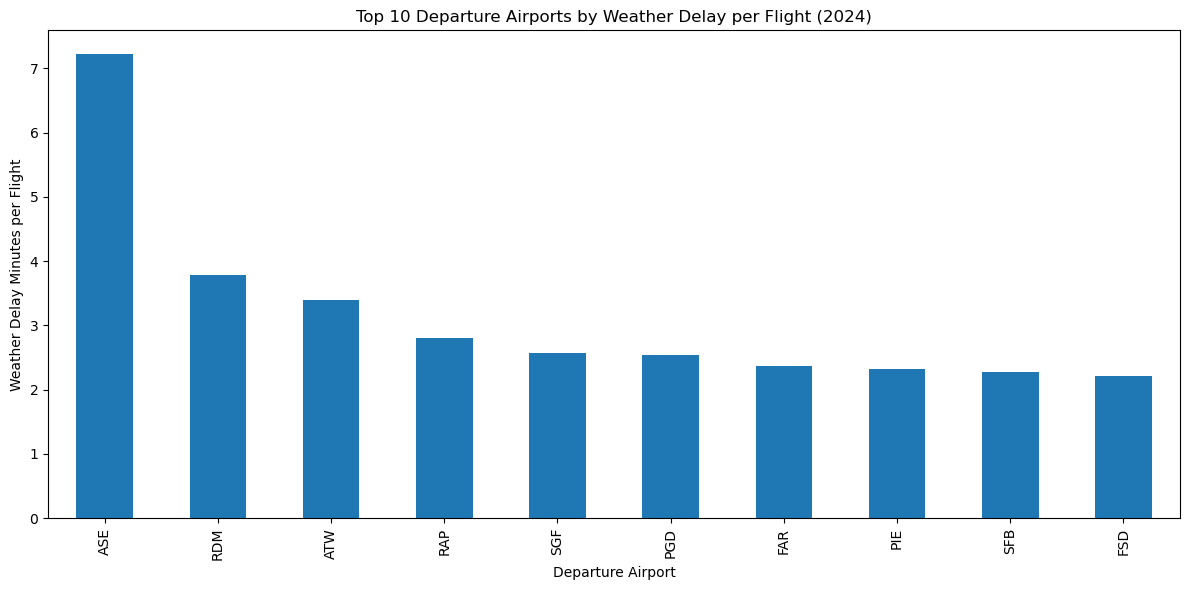

In [46]:
plt.figure(figsize=(12,6))
high_delays_departure.sort_values(by='weather_per_flight', ascending=False).head(10)['weather_per_flight'].plot(kind='bar')
plt.title('Top 10 Departure Airports by Weather Delay per Flight (2024)')
plt.xlabel('Departure Airport')
plt.ylabel('Weather Delay Minutes per Flight')
plt.tight_layout()
plt.show()

**Weather Delays per Flight**

To identify airports with a relatively high weather-related delay burden, I filtered the departure data to include only airports with at least 5,000 flights in 2024.

I then calculated and ranked the average weather delay minutes per flight in descending order.

This approach reduces the influence of airports with very low flight volumes while highlighting airports with comparatively high weather-related delays.

**Important:** The metric represents total weather delay minutes divided by the total number of flights. It does not indicate the average delay of only those flights that were actually affected by weather.

In [41]:
delays_arrival = (
    df.groupby('dest')
    .agg(
        flights=('dest', 'size'),
        carrier_delay=('carrier_delay', 'sum'),
        weather_delay=('weather_delay', 'sum'),
        nas_delay=('nas_delay', 'sum'),
        security_delay=('security_delay', 'sum'),
        late_aircraft_delay=('late_aircraft_delay', 'sum')
    )
)

delays_arrival['carrier_per_flight'] = (delays_arrival['carrier_delay'] / delays_arrival['flights'])
delays_arrival['weather_per_flight'] = (delays_arrival['weather_delay'] / delays_arrival['flights'])
delays_arrival['nas_per_flight'] = (delays_arrival['nas_delay'] / delays_arrival['flights'])
delays_arrival['seco_per_flight'] = (delays_arrival['security_delay'] / delays_arrival['flights'])
delays_arrival['late_aircraft_per_flight'] = (delays_arrival['late_aircraft_delay'] / delays_arrival['flights'])

In [42]:
delays_arrival.head(10)

,flights,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,carrier_per_flight,weather_per_flight,nas_per_flight,seco_per_flight,late_aircraft_per_flight
dest,,,,,,,,,,,
ABE,4336,25682,7631,7129,31,30314,5.922970,1.759917,1.644142,0.007149,6.991236
ABI,1757,4625,2706,4501,0,13858,2.632328,1.540125,2.561753,0.000000,7.887308
ABQ,24094,106384,12175,33032,366,135993,4.415373,0.505313,1.370964,0.015191,5.644268
ABR,728,10924,2795,796,0,0,15.005495,3.839286,1.093407,0.000000,0.000000
ABY,765,10955,3001,939,0,58,14.320261,3.922876,1.227451,0.000000,0.075817
ACK,1675,9320,2375,4507,0,5667,5.564179,1.417910,2.690746,0.000000,3.383284
ACT,1087,6710,2805,1951,44,4603,6.172953,2.580497,1.794848,0.040478,4.234591
ACV,1737,9722,7458,6761,5,8315,5.597006,4.293610,3.892343,0.002879,4.786989
ACY,3049,11435,1127,15486,398,15115,3.750410,0.369629,5.079042,0.130535,4.957363
